# Phase 3 - Task 1: Chart Craft

**Business:** NorthStar Goods  
**Phase:** Visualisation and Dashboards

## Objective

To select effective charts for five business questions, apply clear visual design principles, annotate an important finding, and demonstrate how poor chart choices can mislead an audience.



In [11]:
# Load and validate both datasets

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import StrMethodFormatter
import numpy as np

# Set a consistent chart style
plt.style.use("seaborn-v0_8-whitegrid")

# Define the project dataset folder relative to this notebook
DATA_DIR = Path("../../dataset")

# Load both datasets
df = pd.read_csv('../../dataset/northstar_clean.csv')
regions = pd.read_csv('../../dataset/northstar_regions.csv')

# Convert dates into proper datetime values
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
regions["launch_date"] = pd.to_datetime(
    regions["launch_date"], errors="coerce"
)

# Ensure numerical columns are numeric
numeric_columns = [
    "quantity", "unit_price", "discount_pct", "total_amount"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Clean region and payment method text
df["region"] = df["region"].astype("string").str.strip()
df["payment_method"] = (
    df["payment_method"].astype("string").str.strip()
)
regions["region"] = regions["region"].astype("string").str.strip()

# Define consistent colours
ACCENT = "#287D8E"
GREY = "#B8BEC4"
DARK = "#30343B"

# Check the required columns
required_orders = {
    "order_date", "region", "quantity", "discount_pct",
    "payment_method", "total_amount", "returned"
}
required_regions = {
    "region", "regional_manager", "country", "launch_date"
}

assert required_orders.issubset(df.columns), (
    f"Missing order columns: {required_orders - set(df.columns)}"
)
assert required_regions.issubset(regions.columns), (
    f"Missing region columns: {required_regions - set(regions.columns)}"
)

# Check that each region appears only once in the reference table
assert regions["region"].is_unique, (
    "The reference table contains duplicate region names."
)

# Display the loading results
print("DATASET VALIDATION")
print("==================")
print(f"Cleaned orders: {len(df):,} rows")
print(f"Region reference records: {len(regions):,} rows")
print(f"Unique regions in orders: {df['region'].nunique()}")
print(f"Unique regions in reference: {regions['region'].nunique()}")
print(f"Date range: {df['order_date'].min().date()} to "
      f"{df['order_date'].max().date()}")

print("\nOrder dataset columns:")
print(df.columns.tolist())

print("\nRegion reference columns:")
print(regions.columns.tolist())

# Check whether every order region has a matching reference record
unmatched_regions = sorted(
    set(df["region"].dropna()) - set(regions["region"].dropna())
)

print("\nRegions without a reference match:", unmatched_regions)

if unmatched_regions:
    print("Check the region names before interpreting the regional chart.")
else:
    print("All order regions match the reference table.")

DATASET VALIDATION
Cleaned orders: 999 rows
Region reference records: 8 rows
Unique regions in orders: 8
Unique regions in reference: 8
Date range: 2024-01-02 to 2024-12-30

Order dataset columns:
['order_id', 'order_date', 'customer_id', 'region', 'product_category', 'quantity', 'unit_price', 'discount_pct', 'payment_method', 'total_amount', 'returned']

Region reference columns:
['region', 'regional_manager', 'country', 'launch_date']

Regions without a reference match: []
All order regions match the reference table.


### Reusable chart formatting

In [12]:
# Reusable formatting for the business charts

SOURCE_NOTE = (
    "Source: NorthStar Goods cleaned orders and regional reference data. "
    "Revenue and order values are in £; quantities are items per order. "
    "Return rates use orders with known return status."
)

def finish_chart(ax, note=SOURCE_NOTE):
    """Apply consistent chart formatting and a source footer."""

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9, colors=DARK)

    ax.title.set_fontsize(13)
    ax.title.set_fontweight("bold")
    ax.title.set_color(DARK)

    ax.figure.text(
        0.01, 0.015, note,
        ha="left", va="bottom",
        fontsize=8, color="dimgray"
    )

    ax.figure.tight_layout(rect=[0, 0.07, 1, 1])


def sentence_trend_title(series, metric="revenue"):
    """Generate a factual title based on the first and last observations."""

    clean = series.dropna()

    if len(clean) < 2:
        return f"Monthly {metric} requires at least two months of data"

    first_value = clean.iloc[0]
    last_value = clean.iloc[-1]

    if first_value == 0:
        return f"Monthly {metric} changed across the observed period"

    change_pct = (last_value - first_value) / abs(first_value) * 100

    if change_pct > 0:
        return (
            f"Monthly {metric} rose {change_pct:.1f}% "
            "from the first to the last observed month"
        )
    elif change_pct < 0:
        return (
            f"Monthly {metric} fell {abs(change_pct):.1f}% "
            "from the first to the last observed month"
        )
    else:
        return f"Monthly {metric} ended at its starting level"


print("Chart formatting helpers are ready.")

Chart formatting helpers are ready.


## Chart 1: Monthly Revenue Trend

**Business question:** How is monthly revenue trending?

**Chart choice and justification:** A line chart is best for showing how revenue changes over time because the connected monthly values make the overall direction, peaks and dips easy to identify.

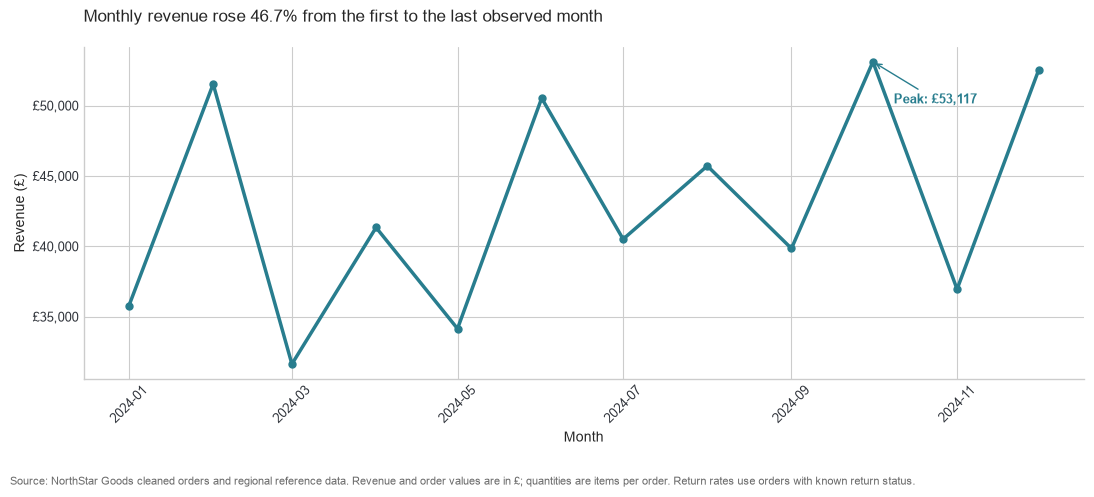

In [13]:
# Calculate total revenue for each month
monthly_revenue = (
    df.dropna(subset=["order_date", "total_amount"])
      .assign(month=lambda data: data["order_date"].dt.to_period("M"))
      .groupby("month")["total_amount"]
      .sum()
      .sort_index()
)

# Convert monthly periods to timestamps for plotting
monthly_dates = monthly_revenue.index.to_timestamp()

# Create the line chart
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    monthly_dates,
    monthly_revenue.values,
    color=ACCENT,
    linewidth=2.5,
    marker="o",
    markersize=5
)

# Label the highest-revenue month with an arrow
peak_index = monthly_revenue.values.argmax()
peak_date = monthly_dates[peak_index]
peak_value = monthly_revenue.iloc[peak_index]

ax.annotate(
    f"Peak: £{peak_value:,.0f}",
    xy=(peak_date, peak_value),
    xytext=(15, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color=ACCENT),
    color=ACCENT,
    fontsize=9,
    fontweight="bold"
)

ax.set_title(
    sentence_trend_title(monthly_revenue, "revenue"),
    loc="left", pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.tick_params(axis="x", rotation=45)

finish_chart(ax)
plt.show()

## Chart 2: Regional Performance

**Business question:** Which regions are pulling their weight?

**Chart choice and justification:** A sorted horizontal bar chart makes regional revenue rankings easy to compare, while the regional reference table adds business context through manager and country information.

Regional reference join:
_merge
both          8
left_only     0
right_only    0


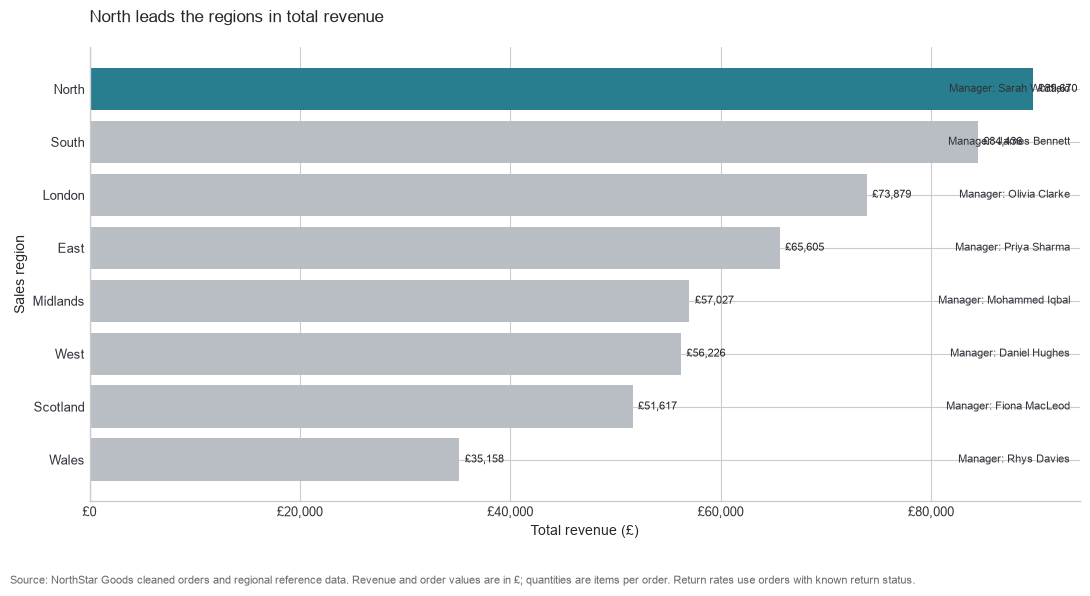

,region,regional_manager,country,launch_date,order_count,revenue
3,North,Sarah Whitfield,England,2019-03-01,169,89670.44
5,South,James Bennett,England,2018-06-15,163,84435.95
1,London,Olivia Clarke,England,2017-05-01,143,73878.89
0,East,Priya Sharma,England,2020-01-10,122,65605.20
2,Midlands,Mohammed Iqbal,England,2018-02-14,111,57027.34
7,West,Daniel Hughes,England,2019-09-05,125,56225.58
4,Scotland,Fiona MacLeod,Scotland,2021-02-20,95,51617.42
6,Wales,Rhys Davies,Wales,2020-11-01,71,35158.23


In [14]:
# Calculate revenue for each region from the cleaned orders
regional_revenue = (
    df.dropna(subset=["region", "total_amount"])
      .groupby("region", as_index=False)
      .agg(
          revenue=("total_amount", "sum"),
          order_count=("order_id", "nunique")
      )
)

# Join the regional reference information
regional_summary = regional_revenue.merge(
    regions[["region", "regional_manager", "country", "launch_date"]],
    on="region",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check the join before interpreting results
print("Regional reference join:")
print(regional_summary["_merge"].value_counts().to_string())

regional_summary = (
    regional_summary.drop(columns="_merge")
    .sort_values("revenue", ascending=True)
)

# Use the accent colour for the leading region
top_region = regional_summary.iloc[-1]

bar_colours = [
    ACCENT if region == top_region["region"] else GREY
    for region in regional_summary["region"]
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    regional_summary["region"],
    regional_summary["revenue"],
    color=bar_colours
)

# Directly label revenue values
ax.bar_label(
    bars,
    labels=[
        f"£{value:,.0f}"
        for value in regional_summary["revenue"]
    ],
    padding=4,
    fontsize=8
)

# Add manager names as context
for position, (_, row) in enumerate(regional_summary.iterrows()):
    manager = row["regional_manager"]
    ax.text(
        0.99, position,
        f"Manager: {manager}",
        transform=ax.get_yaxis_transform(),
        ha="right", va="center",
        fontsize=8, color=DARK
    )

ax.set_title(
    f"{top_region['region']} leads the regions in total revenue",
    loc="left", pad=18
)

ax.set_xlabel("Total revenue (£)")
ax.set_ylabel("Sales region")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.set_xlim(left=0)

finish_chart(ax)
plt.show()

# Display the enriched regional summary for verification
display(
    regional_summary[
        ["region", "regional_manager", "country",
         "launch_date", "order_count", "revenue"]
    ].sort_values("revenue", ascending=False)
)

## Chart 3: Basket Size by Payment Method

**Business question:** How does basket size differ by payment method?

**Chart choice and justification:** A box plot compares the typical number of items per order and the variation in basket sizes across payment methods, including unusually small or large baskets.

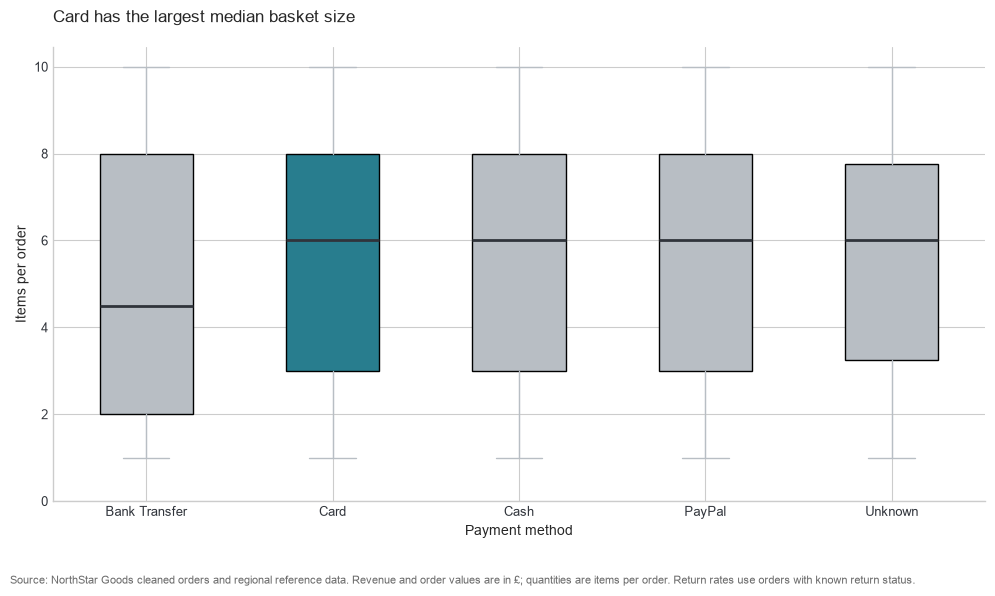

Median items per order by payment method:
payment_method
Card             6.0
PayPal           6.0
Cash             6.0
Unknown          6.0
Bank Transfer    4.5


In [15]:
# Prepare orders with a known payment method and quantity
basket_data = df.dropna(
    subset=["payment_method", "quantity"]
)

# Keep payment methods in a consistent alphabetical order
payment_methods = sorted(basket_data["payment_method"].unique())

basket_values = [
    basket_data.loc[
        basket_data["payment_method"] == method,
        "quantity"
    ].values
    for method in payment_methods
]

# Calculate median basket size for each payment method
basket_medians = [
    basket_data.loc[
        basket_data["payment_method"] == method,
        "quantity"
    ].median()
    for method in payment_methods
]

highest_median_index = int(np.argmax(basket_medians))

fig, ax = plt.subplots(figsize=(10, 6))

box = ax.boxplot(
    basket_values,
    tick_labels=payment_methods,
    patch_artist=True,
    medianprops=dict(color=DARK, linewidth=2),
    whiskerprops=dict(color=GREY),
    capprops=dict(color=GREY),
    flierprops=dict(
        marker="o",
        markersize=3,
        markerfacecolor=GREY,
        markeredgecolor=GREY,
        alpha=0.6
    )
)

# Highlight the payment method with the highest median basket size
for index, patch in enumerate(box["boxes"]):
    patch.set_facecolor(
        ACCENT if index == highest_median_index else GREY
    )

ax.set_title(
    f"{payment_methods[highest_median_index]} has the largest "
    "median basket size",
    loc="left", pad=18
)

ax.set_xlabel("Payment method")
ax.set_ylabel("Items per order")
ax.set_ylim(bottom=0)

finish_chart(ax)
plt.show()

# Show the medians used to identify the leading payment method
print("Median items per order by payment method:")
print(
    basket_data.groupby("payment_method")["quantity"]
    .median()
    .sort_values(ascending=False)
    .to_string()
)

## Chart 4: Discount Depth and Return Rate

**Business question:** Are discount depth and return rate related?

**Chart choice and justification:** A scatter plot shows the observed return rate at each discount level, helping us assess whether an association may exist without implying that discounts cause returns.

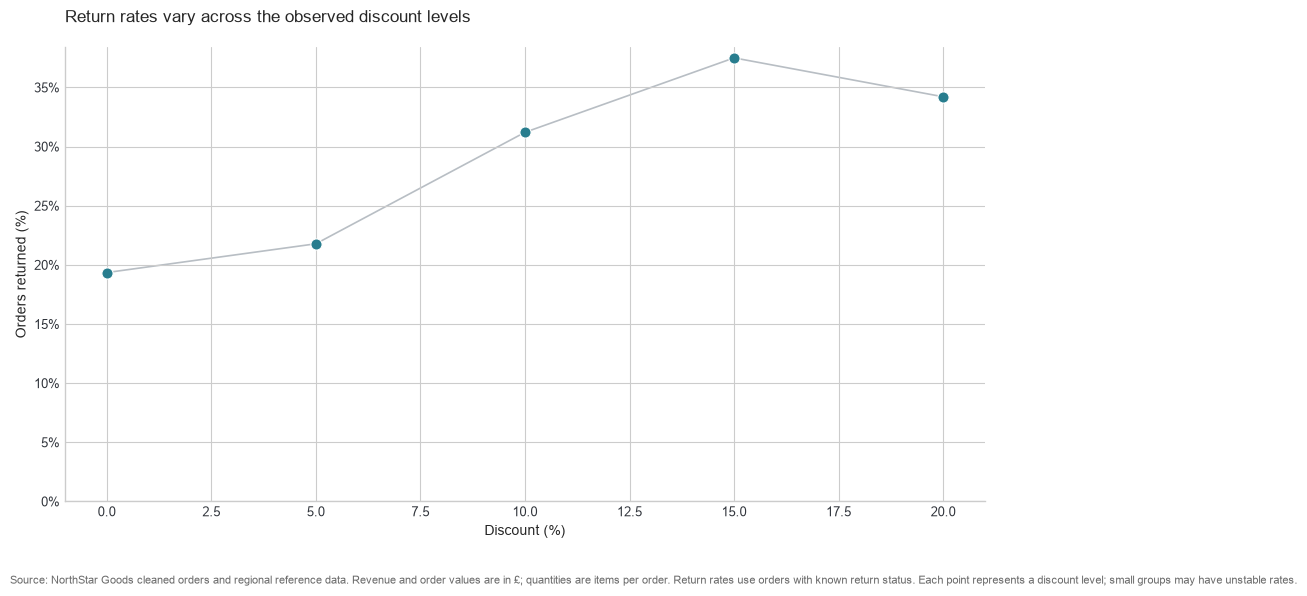

,Orders,Return rate (%)
discount_pct,,
0,522,19.348659
5,202,21.782178
10,141,31.205674
15,96,37.500000
20,38,34.210526


In [16]:
# Standardise the return status values
return_status = (
    df["returned"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Convert recognised values into True/False indicators
return_flag = return_status.map({
    "Y": True,
    "YES": True,
    "TRUE": True,
    "1": True,
    "N": False,
    "NO": False,
    "FALSE": False,
    "0": False
})

# Use only rows with known discount and return information
discount_data = df.assign(
    return_flag=return_flag
).dropna(subset=["discount_pct", "return_flag"])

# Calculate the return rate at each discount level
discount_summary = (
    discount_data.groupby("discount_pct")
    .agg(
        return_rate=("return_flag", "mean"),
        order_count=("return_flag", "size")
    )
    .sort_index()
)

discount_summary["return_rate_pct"] = (
    discount_summary["return_rate"] * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    discount_summary.index,
    discount_summary["return_rate_pct"],
    color=ACCENT,
    s=65,
    edgecolors="white",
    linewidths=0.8
)

# Connect discount levels as a visual guide
ax.plot(
    discount_summary.index,
    discount_summary["return_rate_pct"],
    color=GREY,
    linewidth=1.2,
    zorder=0
)

ax.set_title(
    "Return rates vary across the observed discount levels",
    loc="left", pad=18
)

ax.set_xlabel("Discount (%)")
ax.set_ylabel("Orders returned (%)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
ax.set_ylim(bottom=0)

finish_chart(
    ax,
    SOURCE_NOTE + " Each point represents a discount level; "
    "small groups may have unstable rates."
)
plt.show()

# Show the number of orders behind each point
display(
    discount_summary[
        ["order_count", "return_rate_pct"]
    ].rename(columns={
        "order_count": "Orders",
        "return_rate_pct": "Return rate (%)"
    })
)

## Chart 5: Order-Value Distribution

**Business question:** What does our order-value distribution look like?

**Chart choice and justification:** A histogram shows how frequently order values fall within different ranges, making clusters, skewness and potential extreme values easier to identify.

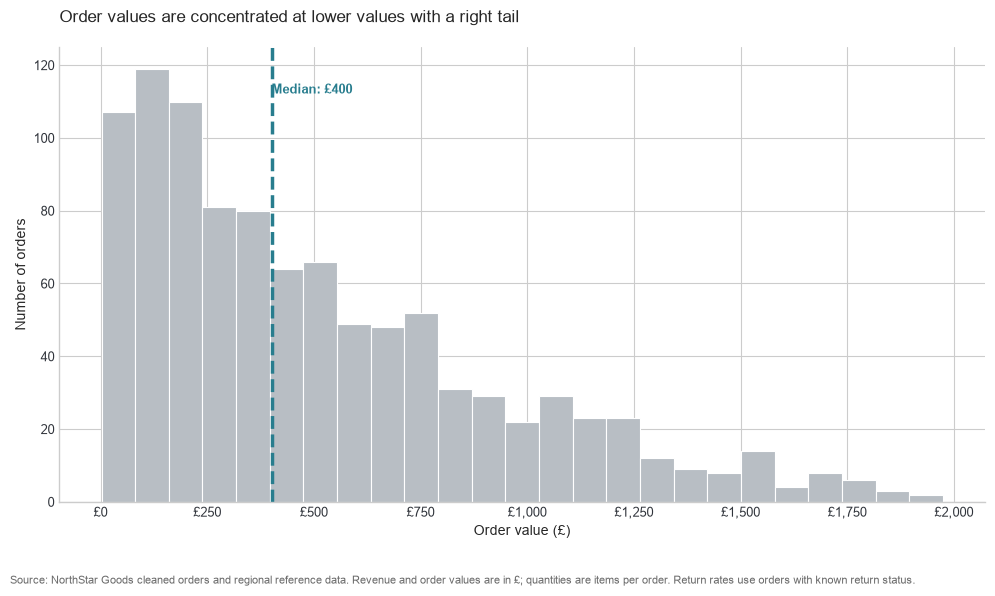

Median order value: £400.41
Order-value skewness: 1.04


In [17]:
# Remove missing order values
order_values = df["total_amount"].dropna()

# Calculate the median for reference
median_order_value = order_values.median()

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the distribution
ax.hist(
    order_values,
    bins=25,
    color=GREY,
    edgecolor="white",
    linewidth=0.8
)

# Highlight the median
ax.axvline(
    median_order_value,
    color=ACCENT,
    linewidth=2.5,
    linestyle="--"
)

# Label the median directly
ax.text(
    median_order_value,
    ax.get_ylim()[1] * 0.92,
    f"Median: £{median_order_value:,.0f}",
    color=ACCENT,
    ha="left",
    va="top",
    fontsize=9,
    fontweight="bold"
)

# Check skewness to make the title evidence-based
skewness = order_values.skew()

if skewness > 0.5:
    distribution_title = "Order values are concentrated at lower values with a right tail"
elif skewness < -0.5:
    distribution_title = "Order values are concentrated at higher values with a left tail"
else:
    distribution_title = "Order values show a relatively balanced distribution"

ax.set_title(distribution_title, loc="left", pad=18)
ax.set_xlabel("Order value (£)")
ax.set_ylabel("Number of orders")
ax.xaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

finish_chart(ax)
plt.show()

print(f"Median order value: £{median_order_value:,.2f}")
print(f"Order-value skewness: {skewness:.2f}")

## Chart Anti-examples

### Anti-example 1: A 3-D-style pie chart

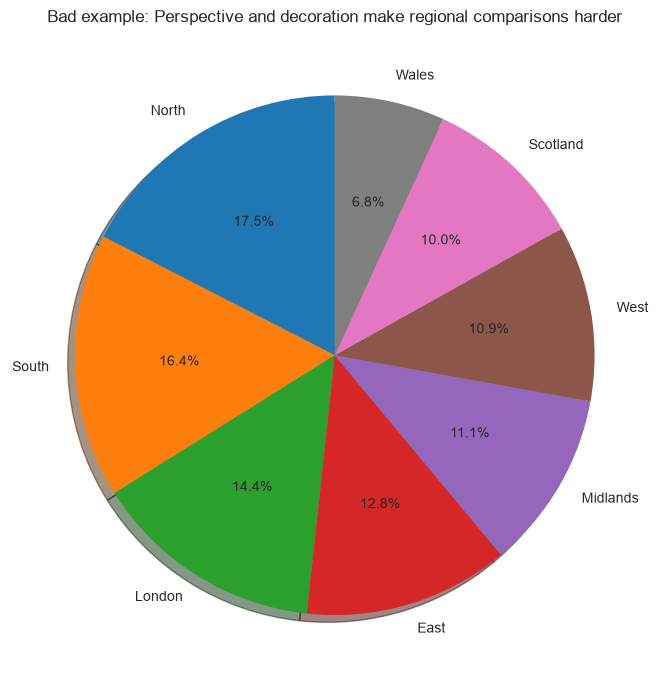

In [18]:
# BAD EXAMPLE 1: A pie chart with a shadow that imitates depth

pie_data = (
    df.dropna(subset=["region", "total_amount"])
      .groupby("region")["total_amount"]
      .sum()
      .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    shadow=True,
    startangle=90
)

ax.set_title(
    "Bad example: Perspective and decoration make regional "
    "comparisons harder"
)

plt.tight_layout()
plt.show()

**Why this chart misleads:** The shadow and depth-like styling add decoration without improving the comparison. Pie slices are already difficult to compare when their values are similar, and perspective can make their apparent sizes less reliable. A sorted two-dimensional bar chart provides a clearer comparison of regional revenue.

### Anti-example 2: A rainbow palette

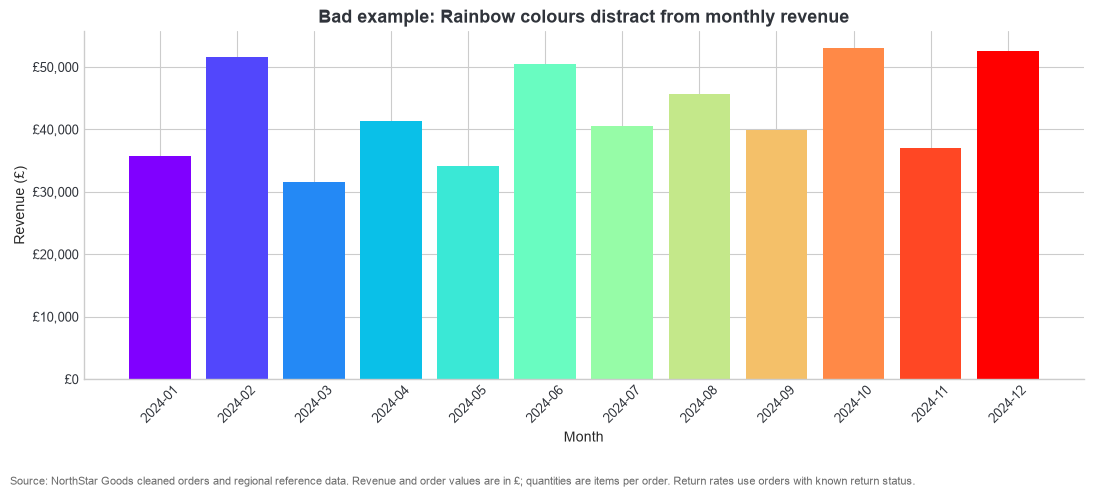

In [19]:
# BAD EXAMPLE 2: Different rainbow colours for the same time series

rainbow_monthly = (
    df.dropna(subset=["order_date", "total_amount"])
      .assign(month=lambda data: data["order_date"].dt.to_period("M"))
      .groupby("month")["total_amount"]
      .sum()
      .sort_index()
)

fig, ax = plt.subplots(figsize=(11, 5))

rainbow_colours = plt.cm.rainbow(
    np.linspace(0, 1, len(rainbow_monthly))
)

ax.bar(
    rainbow_monthly.index.astype(str),
    rainbow_monthly.values,
    color=rainbow_colours
)

ax.set_title(
    "Bad example: Rainbow colours distract from monthly revenue"
)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))
ax.tick_params(axis="x", rotation=45)

finish_chart(ax)
plt.show()

**Why this chart misleads:** A rainbow palette gives each month a different colour even though all bars represent the same measure. The unnecessary colours compete for attention and suggest distinctions that have no business meaning. Using grey for most bars and one accent colour for an important month would make the revenue pattern easier to interpret.

### Anti-example 3: A truncated axis

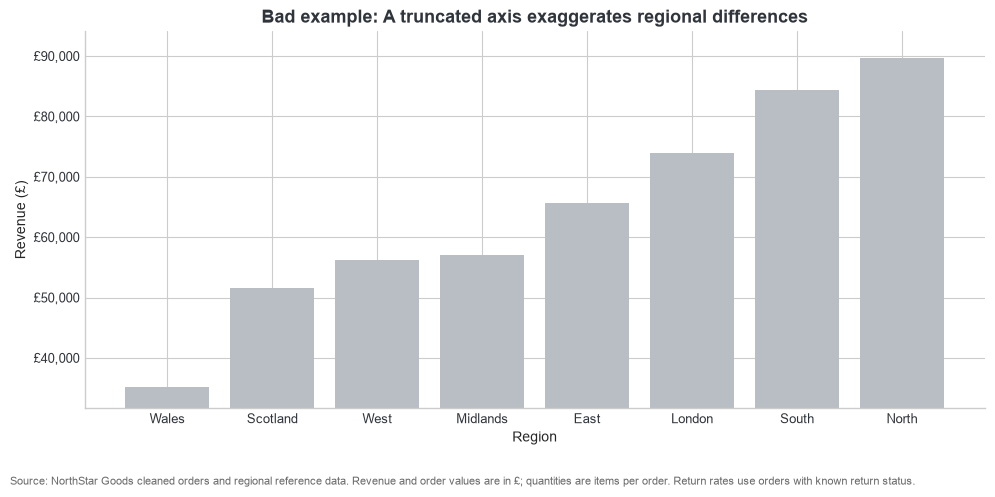

In [20]:
# BAD EXAMPLE 3: Truncating the revenue axis to exaggerate differences

truncated_data = regional_summary.sort_values("revenue")

lowest_revenue = truncated_data["revenue"].min()
highest_revenue = truncated_data["revenue"].max()

if highest_revenue > lowest_revenue:
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(
        truncated_data["region"],
        truncated_data["revenue"],
        color=GREY
    )

    # Deliberately start above zero to exaggerate differences
    lower_limit = max(0, lowest_revenue * 0.90)
    upper_limit = highest_revenue * 1.05

    ax.set_ylim(lower_limit, upper_limit)

    ax.set_title(
        "Bad example: A truncated axis exaggerates regional differences"
    )
    ax.set_xlabel("Region")
    ax.set_ylabel("Revenue (£)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("£{x:,.0f}"))

    finish_chart(ax)
    plt.show()
else:
    print(
        "Regional revenues are equal, so this dataset cannot "
        "demonstrate exaggerated differences with a truncated axis."
    )

**Why this chart misleads:** Starting the vertical axis above zero exaggerates the apparent differences between regions. A small numerical gap can look substantial because the baseline is hidden. For a bar chart comparing absolute revenue, starting at zero generally makes the comparison fairer.